In [1]:
# ============================================================
# ForestGuard AI
# Phase 1: Environment Setup
# ============================================================

import sys
import platform
import importlib.util

print("=" * 60)
print("ForestGuard AI - Environment Check")
print("=" * 60)

# Python environment
print(f"\nPython Version : {sys.version.split()[0]}")
print(f"Platform       : {platform.platform()}")

# Required libraries
required_libraries = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "sklearn",
    "xgboost",
    "joblib",
]

print("\nLibrary Availability:")
print("-" * 40)

for library in required_libraries:
    available = importlib.util.find_spec(library) is not None
    status = "Available" if available else "Not Installed"
    print(f"{library:<15}: {status}")

# GPU availability
print("\nHardware Check:")
print("-" * 40)

try:
    import torch

    gpu_available = torch.cuda.is_available()
    print(f"PyTorch Installed : Yes")
    print(f"GPU Available     : {gpu_available}")

    if gpu_available:
        print(f"GPU Name          : {torch.cuda.get_device_name(0)}")

except ImportError:
    print("PyTorch Installed : No")
    print("GPU Check         : Not available through PyTorch")

print("\nEnvironment check completed.")
print("=" * 60)

ForestGuard AI - Environment Check

Python Version : 3.13.16
Platform       : Linux-6.6.159+-x86_64-with-glibc2.39

Library Availability:
----------------------------------------
numpy          : Available
pandas         : Available
matplotlib     : Available
seaborn        : Available
sklearn        : Available
xgboost        : Available
joblib         : Available

Hardware Check:
----------------------------------------
PyTorch Installed : Yes
GPU Available     : True
GPU Name          : Tesla T4

Environment check completed.


In [2]:
# ============================================================
# ForestGuard AI
# Phase 1: Dependency Version Check
# ============================================================

import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn
import xgboost as xgb
import joblib

print("=" * 60)
print("ForestGuard AI - Dependency Versions")
print("=" * 60)

print(f"NumPy         : {np.__version__}")
print(f"Pandas        : {pd.__version__}")
print(f"Matplotlib    : {matplotlib.__version__}")
print(f"Seaborn       : {sns.__version__}")
print(f"Scikit-learn  : {sklearn.__version__}")
print(f"XGBoost       : {xgb.__version__}")
print(f"Joblib        : {joblib.__version__}")

print("=" * 60)
print("Dependency version check completed.")

ForestGuard AI - Dependency Versions
NumPy         : 2.1.3
Pandas        : 2.2.3
Matplotlib    : 3.10.0
Seaborn       : 0.13.2
Scikit-learn  : 1.6.1
XGBoost       : 3.4.1
Joblib        : 1.6.0
Dependency version check completed.


In [3]:
# ============================================================
# ForestGuard AI
# Phase 1: Load and Verify the Covertype Dataset
# ============================================================

from sklearn.datasets import fetch_covtype

print("Loading the Covertype dataset...")

covtype = fetch_covtype(
    data_home="/content/data",
    download_if_missing=True,
    shuffle=False
)

X = covtype.data
y = covtype.target

print("\n" + "=" * 60)
print("Dataset Verification")
print("=" * 60)

print(f"Number of samples : {X.shape[0]:,}")
print(f"Number of features: {X.shape[1]}")
print(f"Number of classes : {len(set(y))}")

print("\nFeature names:")
print(covtype.feature_names)

print("\nTarget class distribution:")
import pandas as pd

class_distribution = (
    pd.Series(y, name="Cover_Type")
    .value_counts()
    .sort_index()
)

print(class_distribution.to_string())

print("\nFeature matrix shape:", X.shape)
print("Target vector shape :", y.shape)

print("\nDataset loaded successfully.")

Loading the Covertype dataset...

Dataset Verification
Number of samples : 581,012
Number of features: 54
Number of classes : 7

Feature names:
['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_0', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Soil_Type_0', 'Soil_Type_1', 'Soil_Type_2', 'Soil_Type_3', 'Soil_Type_4', 'Soil_Type_5', 'Soil_Type_6', 'Soil_Type_7', 'Soil_Type_8', 'Soil_Type_9', 'Soil_Type_10', 'Soil_Type_11', 'Soil_Type_12', 'Soil_Type_13', 'Soil_Type_14', 'Soil_Type_15', 'Soil_Type_16', 'Soil_Type_17', 'Soil_Type_18', 'Soil_Type_19', 'Soil_Type_20', 'Soil_Type_21', 'Soil_Type_22', 'Soil_Type_23', 'Soil_Type_24', 'Soil_Type_25', 'Soil_Type_26', 'Soil_Type_27', 'Soil_Type_28', 'Soil_Type_29', 'Soil_Type_30', 'Soil_Type_31', 'Soil_Type_32', 'Soil_Type_33', 'Soil_Type

In [4]:
# ============================================================
# ForestGuard AI
# Phase 1: Data Quality Inspection
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("FORESTGUARD AI - DATA QUALITY REPORT")
print("=" * 65)

# 1. Dataset dimensions
print("\n[1] Dataset Dimensions")
print(f"Samples : {X.shape[0]:,}")
print(f"Features: {X.shape[1]}")

# 2. Data types
print("\n[2] Data Types")
print(pd.Series(X.dtype, index=covtype.feature_names).value_counts())

# 3. Missing values
print("\n[3] Missing Values")

missing_values = pd.isna(X).sum()

print(f"Total Missing Values: {missing_values.sum():,}")
print(f"Features with Missing Values: {(missing_values > 0).sum()}")

# 4. Duplicate rows
print("\n[4] Duplicate Rows")

duplicates_count = pd.DataFrame(X).duplicated().sum()

print(f"Duplicate Feature Rows: {duplicates_count:,}")

# 5. Feature statistics
print("\n[5] Feature Statistics")

feature_df = pd.DataFrame(
    X,
    columns=covtype.feature_names
)

print(feature_df.describe().T.to_string())

# 6. Target distribution
print("\n[6] Target Distribution")

target_counts = pd.Series(y).value_counts().sort_index()

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": (target_counts / len(y) * 100).round(2)
})

print(target_summary.to_string())

# 7. Target imbalance
print("\n[7] Class Imbalance Analysis")

majority_class = target_counts.max()
minority_class = target_counts.min()

imbalance_ratio = majority_class / minority_class

print(f"Majority Class Count: {majority_class:,}")
print(f"Minority Class Count: {minority_class:,}")
print(f"Imbalance Ratio     : {imbalance_ratio:.2f}")

print("\n" + "=" * 65)
print("DATA QUALITY INSPECTION COMPLETED")
print("=" * 65)

FORESTGUARD AI - DATA QUALITY REPORT

[1] Dataset Dimensions
Samples : 581,012
Features: 54

[2] Data Types
float64    54
Name: count, dtype: int64

[3] Missing Values
Total Missing Values: 0
Features with Missing Values: 0

[4] Duplicate Rows
Duplicate Feature Rows: 0

[5] Feature Statistics
                                       count         mean          std     min     25%     50%     75%     max
Elevation                           581012.0  2959.365301   279.984734  1859.0  2809.0  2996.0  3163.0  3858.0
Aspect                              581012.0   155.656807   111.913721     0.0    58.0   127.0   260.0   360.0
Slope                               581012.0    14.103704     7.488242     0.0     9.0    13.0    18.0    66.0
Horizontal_Distance_To_Hydrology    581012.0   269.428217   212.549356     0.0   108.0   218.0   384.0  1397.0
Vertical_Distance_To_Hydrology      581012.0    46.418855    58.295232  -173.0     7.0    30.0    69.0   601.0
Horizontal_Distance_To_Roadways     5810

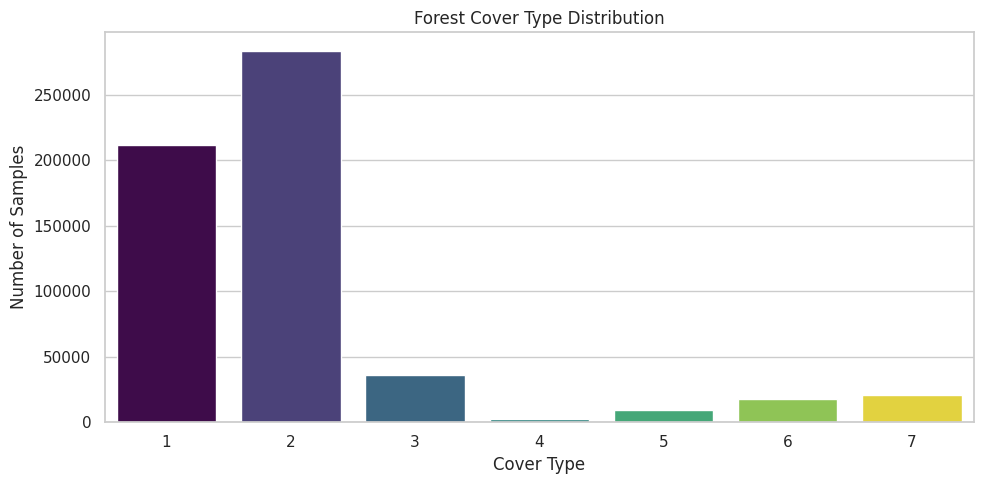

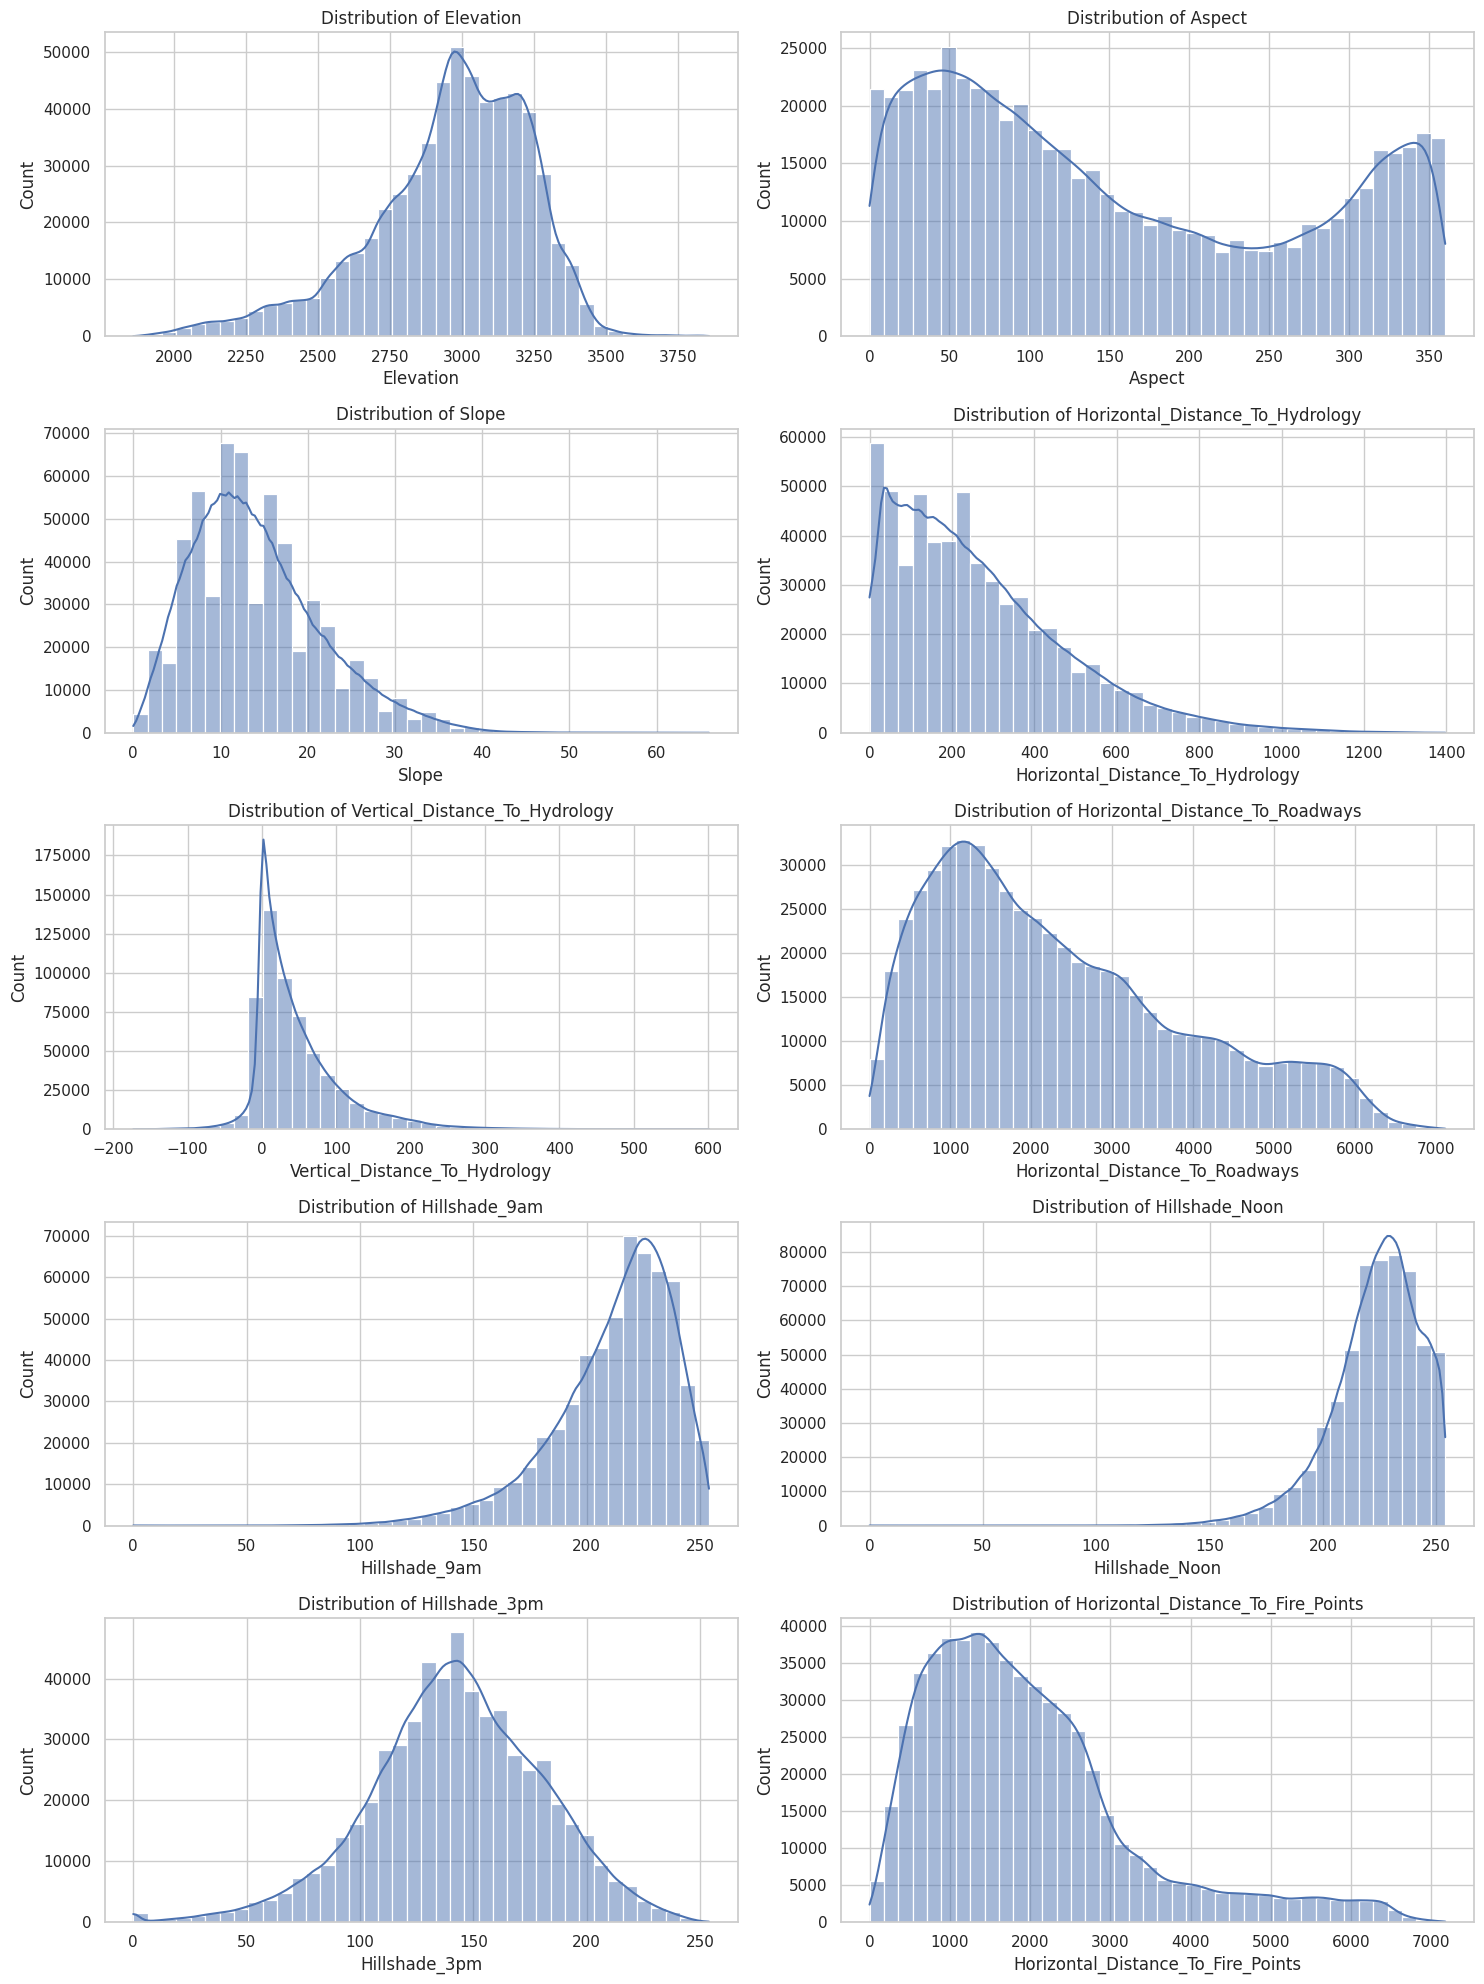

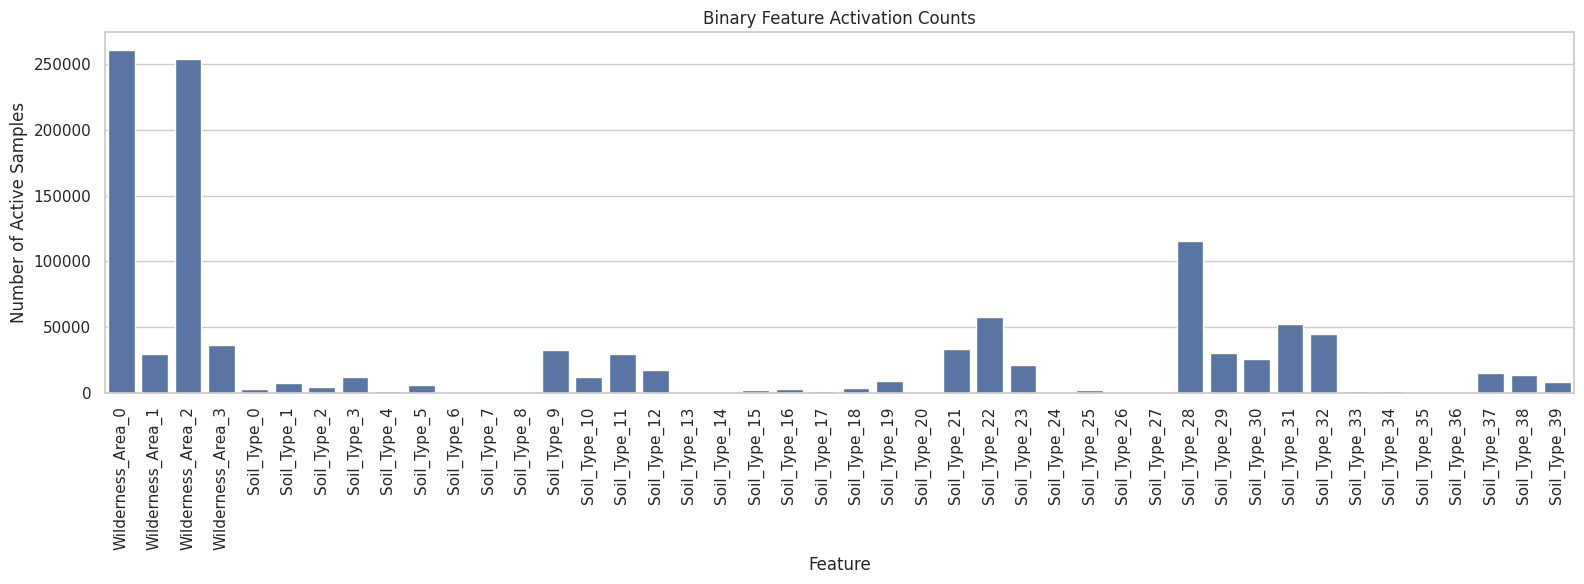

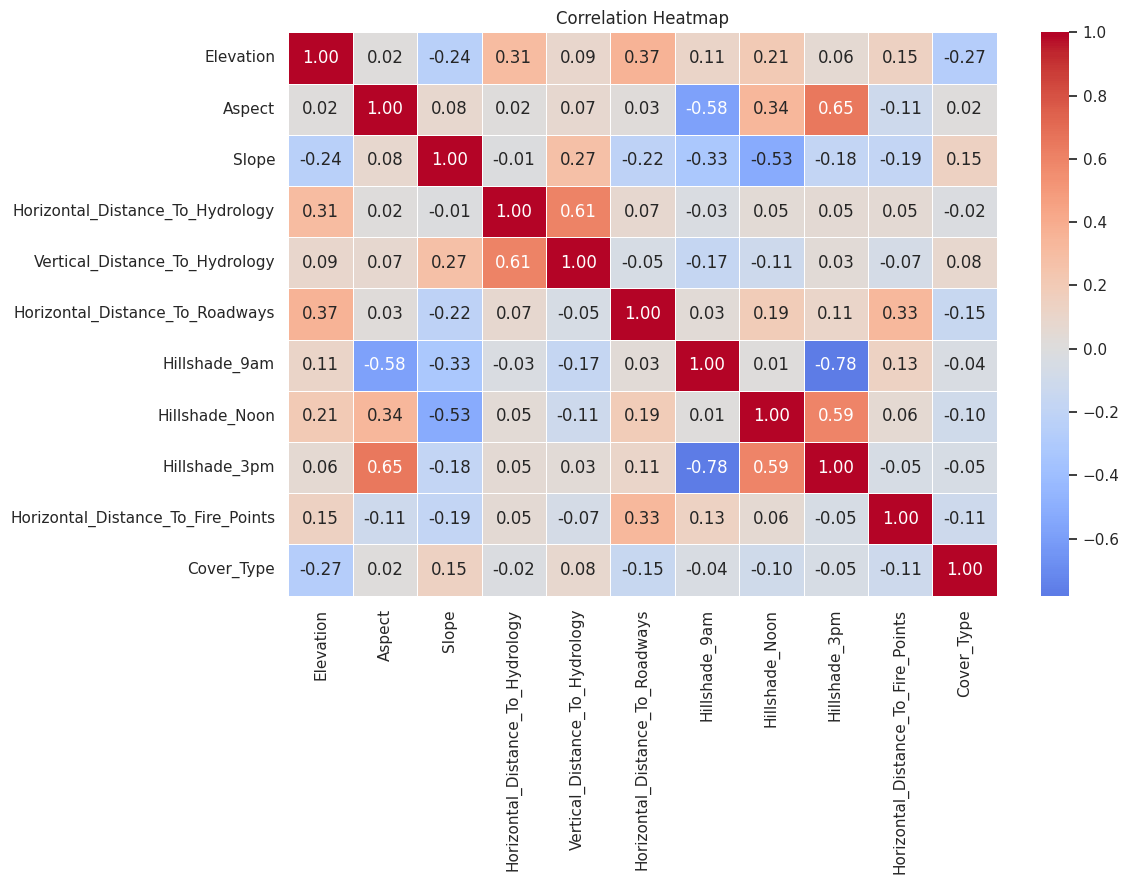

EDA visualizations completed successfully.


In [5]:
# ============================================================
# ForestGuard AI
# Phase 1: Exploratory Data Analysis
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

# Create DataFrame
df = pd.DataFrame(
    X,
    columns=covtype.feature_names
)

df["Cover_Type"] = y

# Separate feature groups
continuous_features = covtype.feature_names[:10]

binary_features = covtype.feature_names[10:]

# ------------------------------------------------------------
# 1. Target Class Distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.countplot(
    x=df["Cover_Type"],
    hue=df["Cover_Type"],
    order=sorted(df["Cover_Type"].unique()),
    palette="viridis",
    legend=False
)

plt.title("Forest Cover Type Distribution")
plt.xlabel("Cover Type")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. Continuous Feature Distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(5, 2, figsize=(15, 20))

for ax, feature in zip(axes.flatten(), continuous_features):

    sns.histplot(
        data=df,
        x=feature,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Binary Feature Distribution
# ------------------------------------------------------------

binary_counts = df[binary_features].sum()

plt.figure(figsize=(16, 6))

sns.barplot(
    x=binary_counts.index,
    y=binary_counts.values
)

plt.title("Binary Feature Activation Counts")
plt.xlabel("Feature")
plt.ylabel("Number of Active Samples")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Correlation Heatmap
# ------------------------------------------------------------

correlation_matrix = df[
    list(continuous_features) + ["Cover_Type"]
].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("EDA visualizations completed successfully.")

In [6]:
# ============================================================
# ForestGuard AI
# Phase 1: Train / Test Split
# ============================================================

from sklearn.model_selection import train_test_split
import pandas as pd

# Preserve feature names
X_df = pd.DataFrame(
    X,
    columns=covtype.feature_names
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_df,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Dataset dimensions
print("=" * 60)
print("TRAIN / TEST SPLIT REPORT")
print("=" * 60)

print(f"\nTraining Samples: {len(X_train):,}")
print(f"Testing Samples : {len(X_test):,}")

print(f"\nTraining Features: {X_train.shape[1]}")
print(f"Testing Features : {X_test.shape[1]}")

# Compare class distributions
train_distribution = (
    pd.Series(y_train)
    .value_counts(normalize=True)
    .sort_index() * 100
)

test_distribution = (
    pd.Series(y_test)
    .value_counts(normalize=True)
    .sort_index() * 100
)

distribution_comparison = pd.DataFrame({
    "Train (%)": train_distribution,
    "Test (%)": test_distribution
})

distribution_comparison.index.name = "Cover_Type"

print("\nClass Distribution Comparison:")
print(distribution_comparison.round(3).to_string())

print("\n" + "=" * 60)
print("TRAIN / TEST SPLIT COMPLETED")
print("=" * 60)

TRAIN / TEST SPLIT REPORT

Training Samples: 464,809
Testing Samples : 116,203

Training Features: 54
Testing Features : 54

Class Distribution Comparison:
            Train (%)  Test (%)
Cover_Type                     
1              36.461    36.460
2              48.760    48.760
3               6.154     6.154
4               0.473     0.472
5               1.634     1.634
6               2.989     2.989
7               3.530     3.530

TRAIN / TEST SPLIT COMPLETED


In [7]:
# ============================================================
# ForestGuard AI
# Phase 2: Baseline Decision Tree Classifier
# ============================================================

import time

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Create Validation Set
# ------------------------------------------------------------

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("=" * 60)
print("BASELINE MODEL - DECISION TREE")
print("=" * 60)

print(f"\nModel Training Samples : {len(X_fit):,}")
print(f"Validation Samples     : {len(X_val):,}")
print(f"Untouched Test Samples : {len(X_test):,}")

# ------------------------------------------------------------
# 2. Initialize Model
# ------------------------------------------------------------

decision_tree = DecisionTreeClassifier(
    random_state=42
)

# ------------------------------------------------------------
# 3. Train Model
# ------------------------------------------------------------

print("\nTraining Decision Tree...")

start_time = time.perf_counter()

decision_tree.fit(X_fit, y_fit)

training_time = time.perf_counter() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

# ------------------------------------------------------------
# 4. Validation Predictions
# ------------------------------------------------------------

y_val_pred = decision_tree.predict(X_val)

# ------------------------------------------------------------
# 5. Evaluation Metrics
# ------------------------------------------------------------

baseline_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Macro Precision": precision_score(
        y_val, y_val_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_val, y_val_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, y_val_pred, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val, y_val_pred, average="weighted", zero_division=0
    )
}

print("\nValidation Metrics:")
print("-" * 40)

for metric, value in baseline_metrics.items():
    print(f"{metric:<20}: {value:.4f}")

print(f"{'Training Time':<20}: {training_time:.2f} seconds")

# ------------------------------------------------------------
# 6. Per-Class Evaluation
# ------------------------------------------------------------

print("\nPer-Class Classification Report:")
print("-" * 60)

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[1, 2, 3, 4, 5, 6, 7],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 7. Model Complexity
# ------------------------------------------------------------

print("\nModel Complexity:")
print("-" * 40)
print(f"Tree Depth : {decision_tree.get_depth()}")
print(f"Leaf Nodes : {decision_tree.get_n_leaves()}")
print(f"Node Count : {decision_tree.tree_.node_count}")

print("\n" + "=" * 60)
print("BASELINE EVALUATION COMPLETED")
print("=" * 60)

BASELINE MODEL - DECISION TREE

Model Training Samples : 371,847
Validation Samples     : 92,962
Untouched Test Samples : 116,203

Training Decision Tree...
Training completed in 8.15 seconds.

Validation Metrics:
----------------------------------------
Accuracy            : 0.9313
Macro Precision     : 0.8848
Macro Recall        : 0.8856
Macro F1            : 0.8852
Weighted F1         : 0.9313
Training Time       : 8.15 seconds

Per-Class Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

           1       0.93      0.93      0.93     33894
           2       0.94      0.94      0.94     45328
           3       0.92      0.92      0.92      5721
           4       0.82      0.79      0.81       439
           5       0.79      0.81      0.80      1519
           6       0.86      0.86      0.86      2779
           7       0.94      0.95      0.94      3282

    accuracy                        

In [8]:
# ============================================================
# ForestGuard AI
# Phase 2: Random Forest Classifier
# ============================================================

import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Initialize Random Forest
# ------------------------------------------------------------

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    verbose=0
)

print("=" * 60)
print("RANDOM FOREST CLASSIFIER")
print("=" * 60)

# ------------------------------------------------------------
# 2. Train Model
# ------------------------------------------------------------

print("\nTraining Random Forest...")

start_time = time.perf_counter()

random_forest.fit(X_fit, y_fit)

rf_training_time = time.perf_counter() - start_time

print(f"Training completed in {rf_training_time:.2f} seconds.")

# ------------------------------------------------------------
# 3. Validation Predictions
# ------------------------------------------------------------

print("\nGenerating validation predictions...")

y_rf_pred = random_forest.predict(X_val)

# ------------------------------------------------------------
# 4. Evaluation Metrics
# ------------------------------------------------------------

rf_metrics = {
    "Accuracy": accuracy_score(y_val, y_rf_pred),
    "Macro Precision": precision_score(
        y_val, y_rf_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_val, y_rf_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, y_rf_pred, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val, y_rf_pred, average="weighted", zero_division=0
    )
}

print("\nValidation Metrics:")
print("-" * 40)

for metric, value in rf_metrics.items():
    print(f"{metric:<20}: {value:.4f}")

print(f"{'Training Time':<20}: {rf_training_time:.2f} seconds")

# ------------------------------------------------------------
# 5. Per-Class Evaluation
# ------------------------------------------------------------

print("\nPer-Class Classification Report:")
print("-" * 60)

print(
    classification_report(
        y_val,
        y_rf_pred,
        labels=[1, 2, 3, 4, 5, 6, 7],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 6. Model Complexity
# ------------------------------------------------------------

total_nodes = sum(
    tree.tree_.node_count
    for tree in random_forest.estimators_
)

print("\nModel Complexity:")
print("-" * 40)
print(f"Number of Trees : {len(random_forest.estimators_)}")
print(f"Total Tree Nodes: {total_nodes:,}")

print("\n" + "=" * 60)
print("RANDOM FOREST EVALUATION COMPLETED")
print("=" * 60)

RANDOM FOREST CLASSIFIER

Training Random Forest...
Training completed in 71.84 seconds.

Generating validation predictions...

Validation Metrics:
----------------------------------------
Accuracy            : 0.9489
Macro Precision     : 0.9378
Macro Recall        : 0.8968
Macro F1            : 0.9157
Weighted F1         : 0.9486
Training Time       : 71.84 seconds

Per-Class Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

           1       0.96      0.94      0.95     33894
           2       0.94      0.97      0.96     45328
           3       0.93      0.96      0.95      5721
           4       0.91      0.83      0.87       439
           5       0.91      0.75      0.82      1519
           6       0.93      0.89      0.91      2779
           7       0.97      0.94      0.96      3282

    accuracy                           0.95     92962
   macro avg       0.94      0.90      0.92    

In [9]:
# ============================================================
# ForestGuard AI
# Phase 2: XGBoost Classifier
# ============================================================

import time

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Initialize XGBoost
# ------------------------------------------------------------

xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=7,
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

print("=" * 60)
print("XGBOOST CLASSIFIER")
print("=" * 60)

# ------------------------------------------------------------
# 2. Train Model
# ------------------------------------------------------------

print("\nTraining XGBoost...")

start_time = time.perf_counter()

xgb_model.fit(X_fit, y_fit - 1)

xgb_training_time = time.perf_counter() - start_time

print(f"Training completed in {xgb_training_time:.2f} seconds.")

# ------------------------------------------------------------
# 3. Validation Predictions
# ------------------------------------------------------------

print("\nGenerating validation predictions...")

y_xgb_pred = xgb_model.predict(X_val) + 1

# ------------------------------------------------------------
# 4. Evaluation Metrics
# ------------------------------------------------------------

xgb_metrics = {
    "Accuracy": accuracy_score(y_val, y_xgb_pred),
    "Macro Precision": precision_score(
        y_val, y_xgb_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_val, y_xgb_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, y_xgb_pred, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val, y_xgb_pred, average="weighted", zero_division=0
    )
}

print("\nValidation Metrics:")
print("-" * 40)

for metric, value in xgb_metrics.items():
    print(f"{metric:<20}: {value:.4f}")

print(f"{'Training Time':<20}: {xgb_training_time:.2f} seconds")

# ------------------------------------------------------------
# 5. Per-Class Evaluation
# ------------------------------------------------------------

print("\nPer-Class Classification Report:")
print("-" * 60)

print(
    classification_report(
        y_val,
        y_xgb_pred,
        labels=[1, 2, 3, 4, 5, 6, 7],
        zero_division=0
    )
)

print("\n" + "=" * 60)
print("XGBOOST EVALUATION COMPLETED")
print("=" * 60)

XGBOOST CLASSIFIER

Training XGBoost...
Training completed in 67.51 seconds.

Generating validation predictions...

Validation Metrics:
----------------------------------------
Accuracy            : 0.8775
Macro Precision     : 0.8925
Macro Recall        : 0.8369
Macro F1            : 0.8607
Weighted F1         : 0.8769
Training Time       : 67.51 seconds

Per-Class Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

           1       0.88      0.84      0.86     33894
           2       0.87      0.91      0.89     45328
           3       0.90      0.91      0.91      5721
           4       0.90      0.85      0.87       439
           5       0.89      0.61      0.72      1519
           6       0.85      0.82      0.83      2779
           7       0.96      0.92      0.94      3282

    accuracy                           0.88     92962
   macro avg       0.89      0.84      0.86     92962
weigh

In [10]:
# ============================================================
# ForestGuard AI
# Phase 2: Imbalance-Aware Random Forest
# ============================================================

import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# 1. Initialize Balanced Random Forest
# ------------------------------------------------------------

balanced_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("=" * 60)
print("BALANCED RANDOM FOREST")
print("=" * 60)

# ------------------------------------------------------------
# 2. Train Model
# ------------------------------------------------------------

print("\nTraining Balanced Random Forest...")

start_time = time.perf_counter()

balanced_rf.fit(X_fit, y_fit)

balanced_rf_training_time = time.perf_counter() - start_time

print(
    f"Training Time: "
    f"{balanced_rf_training_time:.2f} seconds"
)

# ------------------------------------------------------------
# 3. Validation Predictions
# ------------------------------------------------------------

y_balanced_rf_pred = balanced_rf.predict(X_val)

# ------------------------------------------------------------
# 4. Evaluation
# ------------------------------------------------------------

balanced_rf_metrics = {
    "Accuracy": accuracy_score(y_val, y_balanced_rf_pred),
    "Macro Precision": precision_score(
        y_val, y_balanced_rf_pred,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_val, y_balanced_rf_pred,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, y_balanced_rf_pred,
        average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val, y_balanced_rf_pred,
        average="weighted", zero_division=0
    )
}

print("\nValidation Metrics:")
print("-" * 40)

for metric, value in balanced_rf_metrics.items():
    print(f"{metric:<20}: {value:.4f}")

# ------------------------------------------------------------
# 5. Per-Class Evaluation
# ------------------------------------------------------------

print("\nClassification Report:")
print("-" * 60)

print(
    classification_report(
        y_val,
        y_balanced_rf_pred,
        labels=[1, 2, 3, 4, 5, 6, 7],
        zero_division=0
    )
)

print("\n" + "=" * 60)
print("BALANCED RANDOM FOREST COMPLETED")
print("=" * 60)

BALANCED RANDOM FOREST

Training Balanced Random Forest...
Training Time: 72.66 seconds

Validation Metrics:
----------------------------------------
Accuracy            : 0.9500
Macro Precision     : 0.9345
Macro Recall        : 0.8966
Macro F1            : 0.9141
Weighted F1         : 0.9497

Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

           1       0.96      0.94      0.95     33894
           2       0.94      0.97      0.96     45328
           3       0.93      0.96      0.94      5721
           4       0.90      0.83      0.86       439
           5       0.91      0.75      0.82      1519
           6       0.92      0.89      0.90      2779
           7       0.97      0.94      0.96      3282

    accuracy                           0.95     92962
   macro avg       0.93      0.90      0.91     92962
weighted avg       0.95      0.95      0.95     92962


BALANCED RANDOM FOREST

In [11]:
# ============================================================
# ForestGuard AI
# Phase 2: Random Forest Hyperparameter Tuning
# ============================================================

import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# ------------------------------------------------------------
# 1. Define Search Space
# ------------------------------------------------------------

param_distributions = {
    "n_estimators": [100, 150, 200],
    "max_depth": [None, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7]
}

# ------------------------------------------------------------
# 2. Cross-Validation Strategy
# ------------------------------------------------------------

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 3. Initialize Search
# ------------------------------------------------------------

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_distributions,
    n_iter=8,
    scoring="f1_macro",
    cv=cv_strategy,
    verbose=2,
    random_state=42,
    n_jobs=1,
    return_train_score=True
)

print("=" * 60)
print("RANDOM FOREST HYPERPARAMETER TUNING")
print("=" * 60)

print("\nSearch Configuration:")
print("Iterations       : 8")
print("Cross-Validation : 3-Fold Stratified")
print("Scoring          : Macro F1")
print("Search Samples   :", f"{len(X_fit):,}")

# ------------------------------------------------------------
# 4. Execute Search
# ------------------------------------------------------------

start_time = time.perf_counter()

rf_search.fit(X_fit, y_fit)

search_time = time.perf_counter() - start_time

# ------------------------------------------------------------
# 5. Display Results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("HYPERPARAMETER SEARCH RESULTS")
print("=" * 60)

print("\nBest Parameters:")
print(rf_search.best_params_)

print(f"\nBest CV Macro F1: {rf_search.best_score_:.4f}")

print(f"Total Search Time: {search_time:.2f} seconds")

# ------------------------------------------------------------
# 6. Results Summary
# ------------------------------------------------------------

search_results = (
    pd.DataFrame(rf_search.cv_results_)
    .sort_values("rank_test_score")
)

print("\nTop Search Results:")

print(
    search_results[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(8).to_string(index=False)
)

print("\n" + "=" * 60)
print("HYPERPARAMETER TUNING COMPLETED")
print("=" * 60)

RANDOM FOREST HYPERPARAMETER TUNING

Search Configuration:
Iterations       : 8
Cross-Validation : 3-Fold Stratified
Scoring          : Macro F1
Search Samples   : 371,847
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END max_depth=40, max_features=0.7, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time= 2.4min
[CV] END max_depth=40, max_features=0.7, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time= 2.3min
[CV] END max_depth=40, max_features=0.7, min_samples_leaf=2, min_samples_split=5, n_estimators=100; total time= 2.3min
[CV] END max_depth=40, max_features=0.7, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time= 2.3min
[CV] END max_depth=40, max_features=0.7, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time= 2.2min
[CV] END max_depth=40, max_features=0.7, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time= 2.3min
[CV] END max_depth=30, max_features=0.7, min_sample

In [12]:
import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Retrieve the best tuned model
best_rf = rf_search.best_estimator_

# Validation predictions
start_time = time.time()
y_best_rf_pred = best_rf.predict(X_val)
prediction_time = time.time() - start_time

# Calculate validation metrics
tuned_metrics = {
    "Accuracy": accuracy_score(y_val, y_best_rf_pred),
    "Macro Precision": precision_score(
        y_val, y_best_rf_pred, average="macro"
    ),
    "Macro Recall": recall_score(
        y_val, y_best_rf_pred, average="macro"
    ),
    "Macro F1": f1_score(
        y_val, y_best_rf_pred, average="macro"
    ),
    "Weighted F1": f1_score(
        y_val, y_best_rf_pred, average="weighted"
    )
}

print("=" * 60)
print("TUNED RANDOM FOREST — VALIDATION RESULTS")
print("=" * 60)

for metric, value in tuned_metrics.items():
    print(f"{metric:<20}: {value:.4f}")

print(f"\nPrediction Time    : {prediction_time:.4f} seconds")
print(f"Best CV Macro F1   : {rf_search.best_score_:.4f}")

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_val,
        y_best_rf_pred,
        labels=[1, 2, 3, 4, 5, 6, 7],
        zero_division=0
    )
)

TUNED RANDOM FOREST — VALIDATION RESULTS
Accuracy            : 0.9621
Macro Precision     : 0.9442
Macro Recall        : 0.9216
Macro F1            : 0.9324
Weighted F1         : 0.9620

Prediction Time    : 3.1037 seconds
Best CV Macro F1   : 0.9243

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.97      0.95      0.96     33894
           2       0.96      0.98      0.97     45328
           3       0.95      0.97      0.96      5721
           4       0.90      0.86      0.88       439
           5       0.91      0.82      0.86      1519
           6       0.95      0.92      0.93      2779
           7       0.98      0.96      0.97      3282

    accuracy                           0.96     92962
   macro avg       0.94      0.92      0.93     92962
weighted avg       0.96      0.96      0.96     92962



In [13]:
import pandas as pd

comparison_data = [
    {
        "Model": "Decision Tree",
        "Accuracy": 0.9313,
        "Macro Precision": 0.8848,
        "Macro Recall": 0.8856,
        "Macro F1": 0.8852,
        "Weighted F1": 0.9313
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.9489,
        "Macro Precision": 0.9378,
        "Macro Recall": 0.8968,
        "Macro F1": 0.9157,
        "Weighted F1": 0.9486
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.8775,
        "Macro Precision": 0.8925,
        "Macro Recall": 0.8369,
        "Macro F1": 0.8607,
        "Weighted F1": 0.8769
    },
    {
        "Model": "Balanced Random Forest",
        "Accuracy": 0.9500,
        "Macro Precision": 0.9345,
        "Macro Recall": 0.8966,
        "Macro F1": 0.9141,
        "Weighted F1": 0.9497
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": tuned_metrics["Accuracy"],
        "Macro Precision": tuned_metrics["Macro Precision"],
        "Macro Recall": tuned_metrics["Macro Recall"],
        "Macro F1": tuned_metrics["Macro F1"],
        "Weighted F1": tuned_metrics["Weighted F1"]
    }
]

comparison_df = pd.DataFrame(comparison_data)

comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("=" * 75)
print("MODEL COMPARISON — VALIDATION SET")
print("=" * 75)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}"
    }).highlight_max(
        subset=[
            "Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Weighted F1"
        ],
        color="lightgreen"
    )
)

print("\nBest Model:", comparison_df.iloc[0]["Model"])
print("Best Macro F1:", round(comparison_df.iloc[0]["Macro F1"], 4))

MODEL COMPARISON — VALIDATION SET


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Tuned Random Forest,0.9621,0.9442,0.9216,0.9324,0.9620
1,Random Forest,0.9489,0.9378,0.8968,0.9157,0.9486
2,Balanced Random Forest,0.9500,0.9345,0.8966,0.9141,0.9497
3,Decision Tree,0.9313,0.8848,0.8856,0.8852,0.9313
4,XGBoost,0.8775,0.8925,0.8369,0.8607,0.8769



Best Model: Tuned Random Forest
Best Macro F1: 0.9324


In [14]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(
    y_val,
    y_best_rf_pred,
    labels=[1, 2, 3, 4, 5, 6, 7]
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {i}" for i in range(1, 8)],
    columns=[f"Predicted {i}" for i in range(1, 8)]
)

display(cm_df)

print("\nMisclassified samples:", (y_val != y_best_rf_pred).sum())
print("Total validation samples:", len(y_val))

,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6,Predicted 7
Actual 1,32360,1461,1,0,16,3,53
Actual 2,866,44221,74,0,102,48,17
Actual 3,0,67,5552,25,6,71,0
Actual 4,0,0,47,378,0,14,0
Actual 5,14,243,20,0,1239,3,0
Actual 6,5,56,151,18,4,2545,0
Actual 7,123,14,0,0,1,0,3144



Misclassified samples: 3523
Total validation samples: 92962


TOP 20 FEATURE IMPORTANCE


,Feature,Importance
0,Elevation,0.30396
1,Horizontal_Distance_To_Roadways,0.13816
2,Horizontal_Distance_To_Fire_Points,0.13453
3,Horizontal_Distance_To_Hydrology,0.05979
4,Vertical_Distance_To_Hydrology,0.04751
5,Hillshade_Noon,0.03590
6,Aspect,0.03130
7,Wilderness_Area_3,0.03129
8,Hillshade_9am,0.03080
9,Hillshade_3pm,0.02572


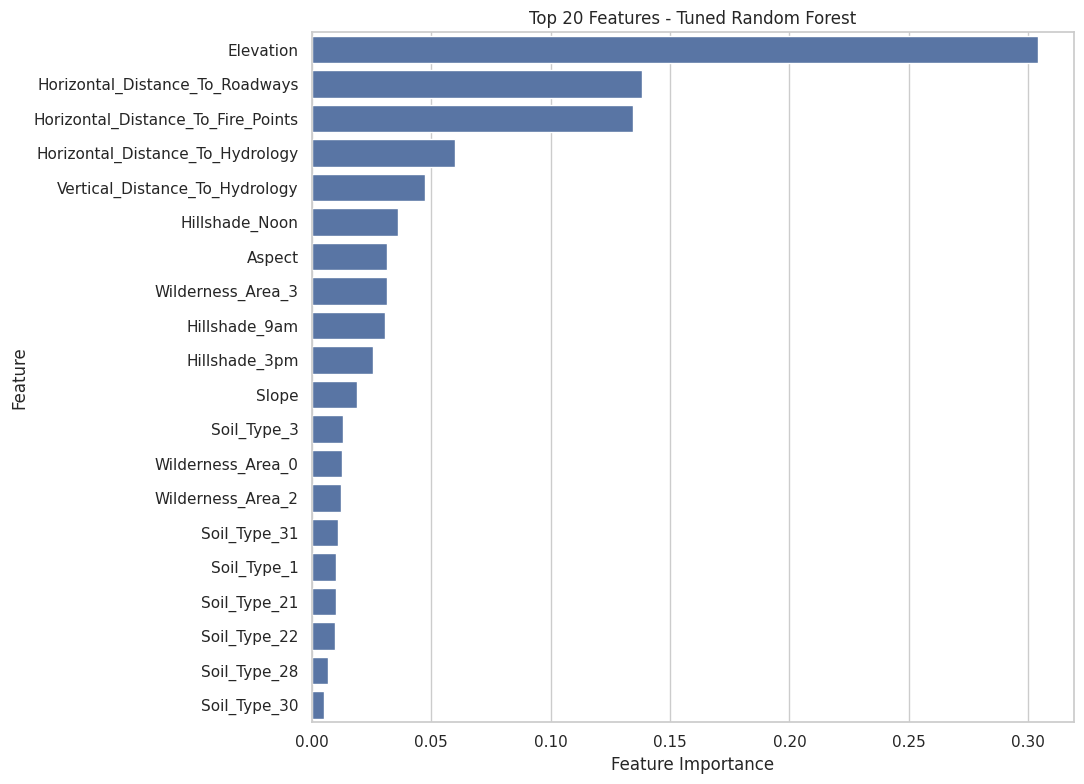

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
top_20_features = feature_importance_df.head(20)

print("=" * 60)
print("TOP 20 FEATURE IMPORTANCE")
print("=" * 60)

display(
    top_20_features.style.format({
        "Importance": "{:.5f}"
    })
)

# Visualize top 20 features
plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_20_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features - Tuned Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [16]:
import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("=" * 65)
print("FINAL MODEL EVALUATION — UNSEEN TEST SET")
print("=" * 65)

# Measure prediction time
start_time = time.time()

y_test_pred = best_rf.predict(X_test)

test_prediction_time = time.time() - start_time

# Calculate final metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Macro Precision": precision_score(
        y_test, y_test_pred, average="macro"
    ),
    "Macro Recall": recall_score(
        y_test, y_test_pred, average="macro"
    ),
    "Macro F1": f1_score(
        y_test, y_test_pred, average="macro"
    ),
    "Weighted F1": f1_score(
        y_test, y_test_pred, average="weighted"
    )
}

for metric, value in test_metrics.items():
    print(f"{metric:<20}: {value:.4f}")

print(f"\nPrediction Time    : {test_prediction_time:.4f} seconds")
print(f"Test Samples       : {len(X_test):,}")

print("\n" + "=" * 65)
print("FINAL CLASSIFICATION REPORT")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[1, 2, 3, 4, 5, 6, 7],
        zero_division=0
    )
)

FINAL MODEL EVALUATION — UNSEEN TEST SET
Accuracy            : 0.9620
Macro Precision     : 0.9473
Macro Recall        : 0.9200
Macro F1            : 0.9329
Weighted F1         : 0.9618

Prediction Time    : 5.7088 seconds
Test Samples       : 116,203

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

           1       0.97      0.95      0.96     42368
           2       0.96      0.98      0.97     56661
           3       0.95      0.96      0.96      7151
           4       0.90      0.86      0.88       549
           5       0.94      0.81      0.87      1899
           6       0.94      0.91      0.93      3473
           7       0.97      0.96      0.96      4102

    accuracy                           0.96    116203
   macro avg       0.95      0.92      0.93    116203
weighted avg       0.96      0.96      0.96    116203



In [17]:
import os
import json
import joblib
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

# Create export directory
export_dir = Path("/content/forestguard_ai_artifacts")
export_dir.mkdir(parents=True, exist_ok=True)

# 1. Save trained model
model_path = export_dir / "forest_cover_model.joblib"
joblib.dump(best_rf, model_path)

# 2. Save final test metrics
pd.DataFrame(
    [test_metrics]
).to_csv(export_dir / "test_metrics.csv", index=False)

# 3. Save model comparison
comparison_df.to_csv(
    export_dir / "model_comparison.csv",
    index=False
)

# 4. Save feature importance
feature_importance_df.to_csv(
    export_dir / "feature_importance.csv",
    index=False
)

# 5. Save test classification report
report = classification_report(
    y_test,
    y_test_pred,
    labels=[1, 2, 3, 4, 5, 6, 7],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    export_dir / "classification_report.csv"
)

# 6. Save test confusion matrix
test_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[1, 2, 3, 4, 5, 6, 7]
)

pd.DataFrame(
    test_cm,
    index=[f"Actual_{i}" for i in range(1, 8)],
    columns=[f"Predicted_{i}" for i in range(1, 8)]
).to_csv(export_dir / "test_confusion_matrix.csv")

# 7. Save feature importance plot
plt.figure(figsize=(11, 8))

sns.barplot(
    data=feature_importance_df.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Feature Importances - ForestGuard AI")
plt.tight_layout()
plt.savefig(
    export_dir / "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# 8. Save test confusion matrix plot
plt.figure(figsize=(10, 8))

sns.heatmap(
    test_cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5, 6, 7],
    yticklabels=[1, 2, 3, 4, 5, 6, 7]
)

plt.title("Test Confusion Matrix - ForestGuard AI")
plt.xlabel("Predicted Cover Type")
plt.ylabel("Actual Cover Type")
plt.tight_layout()

plt.savefig(
    export_dir / "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# 9. Save model metadata
metadata = {
    "project_name": "ForestGuard AI",
    "task": "Multi-class Forest Cover Type Classification",
    "dataset": "UCI Covertype",
    "dataset_samples": 581012,
    "number_of_features": 54,
    "number_of_classes": 7,
    "class_labels": [1, 2, 3, 4, 5, 6, 7],
    "model_type": "RandomForestClassifier",
    "best_parameters": best_rf.get_params(),
    "feature_names": list(X_train.columns),
    "validation_metrics": tuned_metrics,
    "test_metrics": test_metrics,
    "test_samples": len(X_test),
    "prediction_time_seconds": test_prediction_time
}

with open(
    export_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False, default=str)

# 10. Report model size
model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print("=" * 65)
print("FORESTGUARD AI — ARTIFACT EXPORT")
print("=" * 65)

print(f"Model Size: {model_size_mb:.2f} MB")
print(f"Export Directory: {export_dir}")

print("\nExported Files:")
for file_path in sorted(export_dir.iterdir()):
    print(f"{file_path.name:<35} {file_path.stat().st_size / 1024:.2f} KB")

# 11. Create ZIP archive
zip_path = shutil.make_archive(
    "/content/forestguard_ai_artifacts",
    "zip",
    export_dir
)

print("\nZIP archive created successfully:")
print(zip_path)

# 12. Download archive
from google.colab import files
files.download(zip_path)

FORESTGUARD AI — ARTIFACT EXPORT
Model Size: 352.47 MB
Export Directory: /content/forestguard_ai_artifacts

Exported Files:
classification_report.csv           0.72 KB
feature_importance.csv              1.92 KB
feature_importance.png              241.73 KB
forest_cover_model.joblib           360931.95 KB
model_comparison.csv                0.37 KB
model_metadata.json                 2.86 KB
test_confusion_matrix.csv           0.29 KB
test_confusion_matrix.png           197.92 KB
test_metrics.csv                    0.15 KB

ZIP archive created successfully:
/content/forestguard_ai_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>